# Lecture 1 — Orchestrating agents for scientific workflows

*Multi-Agent Systems for Science · Boris Bolliet, University of Cambridge*<br>
*NASA Cosmic Origins Program AI/ML STIG lecture series, 16 November 2026*

This notebook runs one analysis through several organisations of language-model agents and measures each of them. The analysis is a flat-ΛCDM fit of the matter density $\Omega_m$ to the Pantheon+ type Ia supernovae. A deterministic NumPy/SciPy fit gives the reference value. Every agent run is compared with it, and its model calls, tokens and wall time are recorded.

The sections follow the lecture:

1. the task, the data and the reference fit;
2. one agent with a code-execution tool;
3. planning and control, the pattern of CMBAgent;
4. fan-out of workers over subsamples;
5. context isolation between workers;
6. verification of reported numbers against the outputs of the code;
7. the measured cost of each organisation, a checklist and exercises.

The agents are LangGraph graphs. The model is Gemini, called through LangChain's `init_chat_model`; one line selects another provider.

## Setup

The notebook needs a key for the Gemini API, which Google AI Studio issues. On Colab, store it as a secret named `GOOGLE_API_KEY` (key icon in the left panel) and give the notebook access to it. Elsewhere, set the environment variable `GOOGLE_API_KEY` before starting Jupyter.

The saved run made about 110 model calls and took about 5 minutes. On a free-tier key, set `REPEATS = 1` and `REQUESTS_PER_MINUTE = 10` in the configuration cell. A call refused with a rate-limit error (HTTP 429) waits and is sent again.

The agents write Python scripts, and the notebook executes them on the machine that runs the kernel: each script runs in a separate Python process, in a scratch directory, for at most 120 s. The process receives no API keys. It is not a sandbox: a script can read and write any file that your user account can access. Colab or a container is the safe place to run model-written code.

In [1]:
%pip install -q langgraph langchain langchain-google-genai numpy scipy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
%matplotlib inline
import ast, json, operator, os, platform, re, subprocess, sys, tempfile, threading, time, urllib.request, warnings
from collections import Counter
from dataclasses import dataclass
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path
from typing import Annotated, Literal, TypedDict

warnings.filterwarnings("ignore", category=SyntaxWarning)  # emitted by google-genai when it is first compiled
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from langchain.chat_models import init_chat_model
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
from langchain_core.rate_limiters import InMemoryRateLimiter
from langchain_core.tools import tool
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.types import Send
from pydantic import BaseModel, Field
from scipy.integrate import cumulative_trapezoid
from scipy.linalg import cho_factor, cho_solve
from scipy.optimize import brentq, minimize_scalar
from scipy.stats import chi2 as chi2_distribution


def installed(package):
    try:
        return version(package)
    except Exception:
        return None


VERSIONS = {"python": platform.python_version()} | {package: installed(package) for package in [
    "langgraph", "langchain", "langchain-core", "langchain-google-genai", "google-genai",
    "numpy", "scipy", "pandas", "matplotlib", "pydantic"]}
print(VERSIONS)

INK, MUTED, BLUE, ORANGE, AQUA = "#0b0b0b", "#8c8b86", "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "font.size": 10, "axes.titlesize": 10, "axes.labelcolor": INK, "axes.edgecolor": "#52514e",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": 0.6, "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
    "savefig.bbox": "tight"})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
FIG_DIR = Path("../figures") if Path("../figures").is_dir() else Path("figures")
RESULTS_DIR = Path("results")
for directory in (FIG_DIR, RESULTS_DIR):
    directory.mkdir(exist_ok=True)


def save_figure(fig, name):
    for suffix in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{suffix}", dpi=200)

{'python': '3.12.12', 'langgraph': '1.2.22', 'langchain': '1.5.0', 'langchain-core': '1.8.1', 'langchain-google-genai': '4.5.0', 'google-genai': '3.3.0', 'numpy': '2.5.4', 'scipy': '1.18.1', 'pandas': '3.1.1', 'matplotlib': '3.11.2', 'pydantic': '2.14.3'}


### Model and run settings

`MODEL` names a provider and a model in the form `provider:model`. The commented lines show the form for other providers; each needs its own LangChain package and API key. `REPEATS` sets how often each stochastic experiment is repeated. The other settings bound the work that one run can do: the time and the output length of a script, the number of attempts at a failing script, and the number of times a reviewer can send a result back.

In [3]:
MODEL = "google_genai:gemini-3.1-flash-lite"
# MODEL = "openai:<model>"      # OPENAI_API_KEY; pip install langchain-openai
# MODEL = "anthropic:<model>"   # ANTHROPIC_API_KEY; pip install langchain-anthropic
# MODEL = "ollama:<model>"      # local Ollama server; pip install langchain-ollama

REPEATS = 5                 # runs of each stochastic experiment; 1 on a free-tier key
REQUESTS_PER_MINUTE = None  # client-side limit, for example 10 on a free-tier key
EXEC_TIMEOUT = 120          # seconds allowed to one script
OUTPUT_LIMIT = 3000         # characters of script output returned to a model
MAX_TURNS = 10              # model calls of the single agent
MAX_ATTEMPTS = 3            # engineer attempts per step (self-debugging)
MAX_REWORK = 1              # times the reviewer can send a result back
TOLERANCE = 0.005           # agreement with a reference value of Omega_m

In [4]:
if MODEL.startswith("google_genai:"):
    try:
        from google.colab import userdata      # on Colab, the key is a notebook secret
        os.environ["GOOGLE_API_KEY"] = userdata.get("GOOGLE_API_KEY")
    except ImportError:
        pass                                   # elsewhere, the key is an environment variable
    os.environ.pop("GEMINI_API_KEY", None)     # the client prints a notice when both variables are set
    assert os.environ.get("GOOGLE_API_KEY"), "Set GOOGLE_API_KEY as a Colab secret or as an environment variable."

limiter = InMemoryRateLimiter(requests_per_second=REQUESTS_PER_MINUTE / 60) if REQUESTS_PER_MINUTE else None
options = {"max_retries": 1} if MODEL.startswith("google_genai:") else {}  # retries are done by ask() below
llm = init_chat_model(MODEL, rate_limiter=limiter, **options)

### Accounting of calls and tokens

Every model call in the notebook goes through the function `ask`. It sends the call again after a rate-limit or server error, waiting longer each time, and it records the call in a `Ledger`: the agent that made it, its start and end times, and the input, output and reasoning (thinking) tokens that the provider reports. A ledger also records each script execution, so one object holds the bill of one run.

In [5]:
LEDGERS = []          # every ledger of the notebook, for the totals of §7
RETRY_ON = ("429", "RESOURCE_EXHAUSTED", "RateLimit", "rate limit", "500", "503", "UNAVAILABLE", "overloaded")


class Ledger:
    # Model calls and script executions of one run, with times in seconds from the start of the run.

    def __init__(self, name):
        self.name, self.start = name, time.perf_counter()
        self.calls, self.executions = [], []
        self.lock = threading.Lock()   # workers in parallel threads share one ledger
        LEDGERS.append(self)

    def add(self, records, **entry):
        with self.lock:
            records.append(entry)

    def totals(self):
        return {
            "calls": len(self.calls),
            "input_tokens": sum(c["input_tokens"] for c in self.calls),
            "output_tokens": sum(c["output_tokens"] for c in self.calls),
            "reasoning_tokens": sum(c["reasoning_tokens"] for c in self.calls),
            "executions": len(self.executions),
            "failed_executions": sum(not e["ok"] for e in self.executions),
            "rate_limit_wait_s": round(sum(c["wait_s"] for c in self.calls), 1),
            "wall_s": round(time.perf_counter() - self.start, 1),
        }


def ask(model, messages, ledger, agent, attempts=6):
    # One model call, sent again with a growing wait after a rate-limit or server error.
    t0, waited = time.perf_counter(), 0.0
    for attempt in range(attempts):
        try:
            reply = model.invoke(messages)
            break
        except Exception as error:
            message = f"{type(error).__name__}: {error}"
            if attempt == attempts - 1 or not any(marker in message for marker in RETRY_ON):
                raise
            hint = re.search(r"retry in (\d+(?:\.\d+)?)\s*s", message)  # Gemini suggests a delay
            delay = min(float(hint.group(1)) + 1 if hint else 5 * 2**attempt, 90)
            time.sleep(delay)
            waited += delay
    raw = reply["raw"] if isinstance(reply, dict) else reply  # structured output returns a dict
    usage = raw.usage_metadata or {}
    ledger.add(ledger.calls, agent=agent, t0=t0 - ledger.start, t1=time.perf_counter() - ledger.start,
               wait_s=waited, input_tokens=usage.get("input_tokens", 0),
               output_tokens=usage.get("output_tokens", 0),
               reasoning_tokens=(usage.get("output_token_details") or {}).get("reasoning", 0))
    return reply


def ask_structured(schema, messages, ledger, agent):
    # A call whose reply is parsed into the Pydantic class `schema`; one more call if parsing fails.
    model = llm.with_structured_output(schema, include_raw=True)
    for _ in range(2):
        reply = ask(model, messages, ledger, agent)
        if reply["parsed"] is not None:
            return reply["parsed"]
    raise ValueError(f"{agent}: no valid {schema.__name__}: {reply['parsing_error']}")


check = ask(llm, "Reply with the single word: ready", Ledger("check"), "check")
MODEL_REPORTED = check.response_metadata.get("model_name", MODEL)
print(f"{MODEL} -> {check.text!r}; reported model: {MODEL_REPORTED}; usage: {check.usage_metadata}")

google_genai:gemini-3.1-flash-lite -> 'ready'; reported model: gemini-3.1-flash-lite; usage: {'input_tokens': 8, 'output_tokens': 1, 'total_tokens': 9, 'input_token_details': {'cache_read': 0}}


### Execution of model-written code

`run_code` writes a script to a working directory and runs it with the kernel's Python interpreter in a new process. The process gets a reduced environment without API keys, a time limit of `EXEC_TIMEOUT` seconds and the matplotlib backend that writes files. The function returns an `Execution`, whose `report()` is what a model sees: the exit code and the printed output, shortened to `OUTPUT_LIMIT` characters. The end of the output is kept, because a traceback ends there.

Agents report results on a tagged line, `RESULT {...}` from a script or `FINAL {...}` in a reply, with a JSON object that `parse_tagged` reads.

In [6]:
SAFE_ENV = {key: os.environ[key] for key in ("PATH", "HOME", "LANG", "PYTHONPATH", "LD_LIBRARY_PATH", "SYSTEMROOT", "TEMP", "TMP")
            if key in os.environ}


@dataclass
class Execution:
    script: str
    returncode: int
    stdout: str
    stderr: str
    seconds: float

    @property
    def ok(self):
        return self.returncode == 0

    def report(self):
        text = f"{self.script}: exit code {self.returncode} after {self.seconds:.1f} s\n--- stdout ---\n{clip(self.stdout)}"
        return text + (f"\n--- stderr ---\n{clip(self.stderr)}" if self.stderr.strip() else "")


def clip(text, limit=OUTPUT_LIMIT):
    if len(text) <= limit:
        return text
    return text[: limit // 3] + f"\n[... {len(text) - limit} characters omitted ...]\n" + text[-2 * limit // 3:]


def run_code(code, workdir, ledger, agent):
    # Run one script in a fresh Python process inside workdir.
    workdir.mkdir(parents=True, exist_ok=True)
    path = workdir / f"script_{len(list(workdir.glob('script_*.py'))) + 1:02d}.py"
    path.write_text(code)
    t0 = time.perf_counter()
    if not code.strip():
        returncode, stdout, stderr = 1, "", "No Python code was found in the reply."
    else:
        try:
            done = subprocess.run([sys.executable, path.name], cwd=workdir, capture_output=True, text=True,
                                  timeout=EXEC_TIMEOUT, env=SAFE_ENV | {"MPLBACKEND": "Agg"})
            returncode, stdout, stderr = done.returncode, done.stdout, done.stderr
        except subprocess.TimeoutExpired as error:
            stdout = error.stdout.decode() if isinstance(error.stdout, bytes) else (error.stdout or "")
            returncode, stderr = -1, f"TimeoutExpired: the script was stopped after {EXEC_TIMEOUT} s."
    t1 = time.perf_counter()
    error = "" if returncode == 0 else (stderr.strip().splitlines() or ["no message"])[-1][:160]
    ledger.add(ledger.executions, agent=agent, t0=t0 - ledger.start, t1=t1 - ledger.start, ok=returncode == 0,
               error=error)
    return Execution(path.name, returncode, stdout, stderr, t1 - t0)


def extract_code(text):
    # The longest fenced Python block of a reply, or the whole reply if it has none.
    blocks = re.findall(r"```(?:python|py)?[ \t]*\n(.*?)```", text, flags=re.S)
    return max(blocks, key=len) if blocks else text


def parse_tagged(text, tag):
    # The JSON object after the last occurrence of `tag` in text, or None.
    for candidate in reversed(re.findall(re.escape(tag) + r"\W*?(\{[^{}]*\})", text or "", flags=re.S)):
        for parse in (json.loads, ast.literal_eval):
            try:
                return parse(candidate)
            except (ValueError, SyntaxError):
                pass
    return None


def number(value):
    try:
        return float(value)
    except (TypeError, ValueError):
        return None


def show_graph(graph):
    # Print the edges of a compiled graph; -.-> marks a conditional edge.
    for edge in graph.get_graph().edges:
        print(f"{edge.source:>12} {'-.->' if edge.conditional else '--->'} {edge.target}")


RUNS_DIR = Path(tempfile.mkdtemp(prefix="l01_runs_"))
print("Scripts written by the agents are saved under", RUNS_DIR)

Scripts written by the agents are saved under <scratch>/l01_runs_003avuk0


## 1. The task and the data

### 1.1. Pantheon+ distances

Pantheon+ (Scolnic et al. 2022; Brout et al. 2022) is a compilation of 1701 light curves of type Ia supernovae from 18 surveys. The file `Pantheon+SH0ES.dat` has one row per light curve, so a supernova observed by two surveys has two rows. The fit uses four of its columns:

| Column | Content |
|---|---|
| `zHD` | Hubble-diagram redshift, corrected to the CMB frame and for peculiar velocities |
| `zHEL` | heliocentric redshift |
| `m_b_corr` | standardised peak magnitude $m_b$, corrected for light-curve shape, colour and selection biases |
| `m_b_corr_err_DIAG` | uncertainty of `m_b_corr` for each supernova, without correlations |

The file `Pantheon+SH0ES_STAT+SYS.cov` holds the 1701 × 1701 covariance matrix of `m_b_corr`, with statistical and systematic terms. Its first line is $N = 1701$; the $N^2$ entries follow, one per line. The data release states that `m_b_corr_err_DIAG` is for plotting only and that cosmological fits must use the full covariance matrix.

The next cell downloads both files (34 MB) and the release's README into `data/`, reads them, and prints the warning lines of the README.

In [7]:
DATA_URL = "https://raw.githubusercontent.com/PantheonPlusSH0ES/DataRelease/main/Pantheon%2B_Data/4_DISTANCES_AND_COVAR/"
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
TABLE_PATH = (DATA_DIR / "Pantheon+SH0ES.dat").resolve()
COV_PATH = (DATA_DIR / "Pantheon+SH0ES_STAT+SYS.cov").resolve()
README_PATH = (DATA_DIR / "README.txt").resolve()
for path, remote in [(TABLE_PATH, "Pantheon%2BSH0ES.dat"), (COV_PATH, "Pantheon%2BSH0ES_STAT%2BSYS.cov"),
                     (README_PATH, "README")]:
    if not path.exists():
        partial = path.with_suffix(".part")
        urllib.request.urlretrieve(DATA_URL + remote, partial)
        partial.rename(path)
    print(f"{path.name}: {path.stat().st_size / 1e6:.1f} MB")

table = pd.read_csv(TABLE_PATH, sep=r"\s+")
values = np.loadtxt(COV_PATH)
n = int(values[0])
cov = values[1:].reshape(n, n)
print(f"{len(table)} rows, {table.CID.nunique()} distinct supernova names (CID), {table.IDSURVEY.nunique()} survey codes")
print(f"covariance matrix: {cov.shape}; zHD from {table.zHD.min():.4f} to {table.zHD.max():.2f}")
README_TEXT = README_PATH.read_text()
print("\n".join(line.strip() for line in README_TEXT.splitlines() if "WARNING" in line))

Pantheon+SH0ES.dat: 0.6 MB
Pantheon+SH0ES_STAT+SYS.cov: 33.3 MB
README.txt: 0.0 MB
1701 rows, 1543 distinct supernova names (CID), 20 survey codes
covariance matrix: (1701, 1701); zHD from 0.0012 to 2.26
m_b_corr_err_DIAG - Tripp1998 corrected/standardized m_b magnitude uncertainty as determined from the diagonal of the covariance matrix. **WARNING, DO NOT FIT COSMOLOGICAL PARAMETERS WITH THESE UNCERTAINTIES. YOU MUST USE THE FULL COVARIANCE. THIS IS ONLY FOR PLOTTING/VISUAL PURPOSES**
MU_SH0ES_ERR_DIAG - Uncertainty on MU_SH0ES as determined from the diagonal of the covariance matrix. **WARNING, DO NOT FIT COSMOLOGICAL PARAMETERS WITH THESE UNCERTAINTIES. YOU MUST USE THE FULL COVARIANCE. THIS IS ONLY FOR PLOTTING/VISUAL PURPOSES**


### 1.2. Analysis conventions

The fit depends on choices that the data files do not record: which supernovae enter, which redshift goes into each term of the model, and which uncertainties weight the residuals. The class `AnalysisSpec` collects these choices in one object, the analysis specification. The reference fit reads it, the task given to the agents is printed from it, and §5 passes it to workers.

In [8]:
class AnalysisSpec(BaseModel):
    z_min: float = 0.01                                  # keep supernovae with z_column > z_min
    z_column: str = "zHD"                                # redshift in the comoving distance D_C
    z_hel_column: str = "zHEL"                           # redshift in the factor (1 + z) of d_L
    H0: float = 70.0                                     # km/s/Mpc; degenerate with the offset M
    covariance: Literal["full", "diagonal"] = "full"     # STAT+SYS matrix or m_b_corr_err_DIAG**2

    def requirements(self):
        weights = ("the full statistical and systematic covariance matrix, restricted to the rows and columns "
                   "of the selected supernovae" if self.covariance == "full"
                   else "the diagonal uncertainties m_b_corr_err_DIAG")
        return "\n".join([
            f"1. Use the light curves (table rows) with {self.z_column} > {self.z_min:g}.",
            f"2. Model: m_b_corr = 5 log10(d_L / Mpc) + 25 + M, with d_L = (1 + {self.z_hel_column}) D_C({self.z_column}) "
            f"and D_C the comoving distance of a flat LCDM cosmology with H0 = {self.H0:g} km/s/Mpc.",
            "3. M is a free offset: minimise chi^2 over M analytically at each Omega_m.",
            f"4. Weight the residuals with {weights}.",
            "5. Report Omega_m, its 1-sigma uncertainty from Delta chi^2 = 1, chi^2 at the minimum "
            "and the number of light curves (table rows) used.",
        ])


SPEC = AnalysisSpec()
print(SPEC.requirements())

1. Use the light curves (table rows) with zHD > 0.01.
2. Model: m_b_corr = 5 log10(d_L / Mpc) + 25 + M, with d_L = (1 + zHEL) D_C(zHD) and D_C the comoving distance of a flat LCDM cosmology with H0 = 70 km/s/Mpc.
3. M is a free offset: minimise chi^2 over M analytically at each Omega_m.
4. Weight the residuals with the full statistical and systematic covariance matrix, restricted to the rows and columns of the selected supernovae.
5. Report Omega_m, its 1-sigma uncertainty from Delta chi^2 = 1, chi^2 at the minimum and the number of light curves (table rows) used.


### 1.3. Reference fit

For a flat ΛCDM cosmology, the comoving distance and the luminosity distance are

$$D_C(z) = \frac{c}{H_0}\int_0^{z}\frac{\mathrm{d}z'}{E(z')},\qquad E(z) = \sqrt{\Omega_m(1+z)^3 + 1 - \Omega_m},\qquad d_L = (1+z_\mathrm{hel})\,D_C(z_\mathrm{HD}),$$

and the model magnitude is $5\log_{10}(d_L/\mathrm{Mpc}) + 25 + M$. The offset $M$ combines the absolute magnitude of a type Ia supernova with $\log_{10} H_0$, so $H_0$ can be fixed at 70 km/s/Mpc without loss. With $\boldsymbol r$ the vector of residuals $m_{b,\mathrm{corr}} - 5\log_{10}(d_L/\mathrm{Mpc}) - 25$, $C$ the covariance matrix and $\boldsymbol 1$ a vector of ones, the chi-squared is a quadratic function of $M$:

$$\chi^2(\Omega_m, M) = (\boldsymbol r - M\boldsymbol 1)^\top C^{-1}(\boldsymbol r - M\boldsymbol 1).$$

Its minimum over $M$ has a closed form,

$$\chi^2_\mathrm{min}(\Omega_m) = \boldsymbol r^\top C^{-1}\boldsymbol r - \frac{(\boldsymbol 1^\top C^{-1}\boldsymbol r)^2}{\boldsymbol 1^\top C^{-1}\boldsymbol 1},\qquad \hat M = \frac{\boldsymbol 1^\top C^{-1}\boldsymbol r}{\boldsymbol 1^\top C^{-1}\boldsymbol 1}.$$

`reference_fit` minimises $\chi^2_\mathrm{min}$ over $\Omega_m$ and takes the 1σ interval where $\chi^2$ exceeds its minimum by 1. It solves linear systems with the Cholesky factor of $C$ instead of forming $C^{-1}$, and it integrates $1/E(z)$ once on a fine grid of redshifts.

In [9]:
C_KM_S = 299792.458


def distance_modulus(omega_m, z, z_hel, H0):
    # 5 log10(d_L / Mpc) + 25 in flat LCDM; D_C is integrated on a grid and interpolated.
    grid = np.linspace(0.0, np.max(z) * 1.001, 20001)
    inverse_E = 1.0 / np.sqrt(omega_m * (1 + grid) ** 3 + 1 - omega_m)
    D_C = cumulative_trapezoid(inverse_E, grid, initial=0.0) * C_KM_S / H0
    return 5 * np.log10((1 + z_hel) * np.interp(z, grid, D_C)) + 25


def reference_fit(spec=SPEC, rows=None):
    # Omega_m with M minimised analytically; `rows` (boolean array) restricts the sample.
    keep = (table[spec.z_column] > spec.z_min).to_numpy()
    if rows is not None:
        keep = keep & rows
    data = table[keep]
    m = data["m_b_corr"].to_numpy()
    z, z_hel = data[spec.z_column].to_numpy(), data[spec.z_hel_column].to_numpy()
    C = cov[np.ix_(keep, keep)] if spec.covariance == "full" else np.diag(data["m_b_corr_err_DIAG"].to_numpy() ** 2)
    factor = cho_factor(C)
    ones = np.ones(len(m))
    ones_C_ones = ones @ cho_solve(factor, ones)

    def chi2(omega_m):
        r = m - distance_modulus(omega_m, z, z_hel, spec.H0)
        C_r = cho_solve(factor, r)
        return r @ C_r - (ones @ C_r) ** 2 / ones_C_ones

    best = minimize_scalar(chi2, bounds=(0.01, 0.99), method="bounded", options={"xatol": 1e-6})
    lower = brentq(lambda x: chi2(x) - best.fun - 1, 0.001, best.x)
    upper = brentq(lambda x: chi2(x) - best.fun - 1, best.x, 0.999)
    r = m - distance_modulus(best.x, z, z_hel, spec.H0)
    return {"omega_m": best.x, "omega_m_err": (upper - lower) / 2, "chi2_min": best.fun,
            "n_sn": int(keep.sum()), "M": (ones @ cho_solve(factor, r)) / ones_C_ones}


REFERENCE = reference_fit(SPEC)
REFERENCE_DIAG = reference_fit(SPEC.model_copy(update={"covariance": "diagonal"}))
for label, fit in [("full covariance", REFERENCE), ("diagonal errors", REFERENCE_DIAG)]:
    print(f"{label:16s} Omega_m = {fit['omega_m']:.4f} ± {fit['omega_m_err']:.4f}   "
          f"chi2_min = {fit['chi2_min']:.1f}   N = {fit['n_sn']}   M = {fit['M']:.3f}")
print("Brout et al. (2022), Pantheon+ alone: Omega_m = 0.334 ± 0.018")
selected = table[table[SPEC.z_column] > SPEC.z_min]
print(f"{SPEC.z_column} > {SPEC.z_min:g}: {len(selected)} light curves of {selected.CID.nunique()} distinct supernovae")

full covariance  Omega_m = 0.3316 ± 0.0182   chi2_min = 1402.9   N = 1590   M = -19.351
diagonal errors  Omega_m = 0.3504 ± 0.0188   chi2_min = 697.3   N = 1590   M = -19.344
Brout et al. (2022), Pantheon+ alone: Omega_m = 0.334 ± 0.018
zHD > 0.01: 1590 light curves of 1473 distinct supernovae


The full-covariance fit reproduces the published value, 0.334 ± 0.018, to within 0.003. The fit with diagonal errors gives a value higher by about one standard deviation, with a similar uncertainty. Only its $\chi^2$, 697 for 1590 light curves, hints that these weights do not describe the scatter of the data. The 1590 light curves after the cut belong to 1473 distinct supernovae, because some supernovae were observed by several surveys.

Other conventions also move the result. The next cell repeats the fit with one convention changed at a time.

In [10]:
VARIANTS = {
    "reference": SPEC,
    "diagonal errors": SPEC.model_copy(update={"covariance": "diagonal"}),
    "zCMB in place of zHD": SPEC.model_copy(update={"z_column": "zCMB"}),
    "(1 + zHD) in place of (1 + zHEL)": SPEC.model_copy(update={"z_hel_column": "zHD"}),
    "no redshift cut": SPEC.model_copy(update={"z_min": 0.0}),
}
variant_fits = {name: reference_fit(spec) for name, spec in VARIANTS.items()}
display(pd.DataFrame([{
    "convention": name, "N": fit["n_sn"], "Omega_m": round(fit["omega_m"], 4), "sigma": round(fit["omega_m_err"], 4),
    "shift / sigma": round((fit["omega_m"] - REFERENCE["omega_m"]) / REFERENCE["omega_m_err"], 2),
} for name, fit in variant_fits.items()]))

,convention,N,Omega_m,sigma,shift / sigma
0,reference,1590,0.3316,0.0182,0.00
1,diagonal errors,1590,0.3504,0.0188,1.03
2,zCMB in place of zHD,1588,0.3471,0.0187,0.86
3,(1 + zHD) in place of (1 + zHEL),1590,0.3306,0.0182,-0.05
4,no redshift cut,1701,0.3624,0.0187,1.69


Using `zCMB`, which lacks the peculiar-velocity correction, or keeping the supernovae below $z = 0.01$, whose redshifts are strongly affected by peculiar velocities, shifts $\Omega_m$ by about one standard deviation or more. The choice of redshift in the factor $(1+z)$ changes it by a small fraction of one. The figure shows the data, the two fits and their difference.

Difference between the two models at the data: -0.026 to +0.007 mag; median m_b_corr_err_DIAG: 0.213 mag


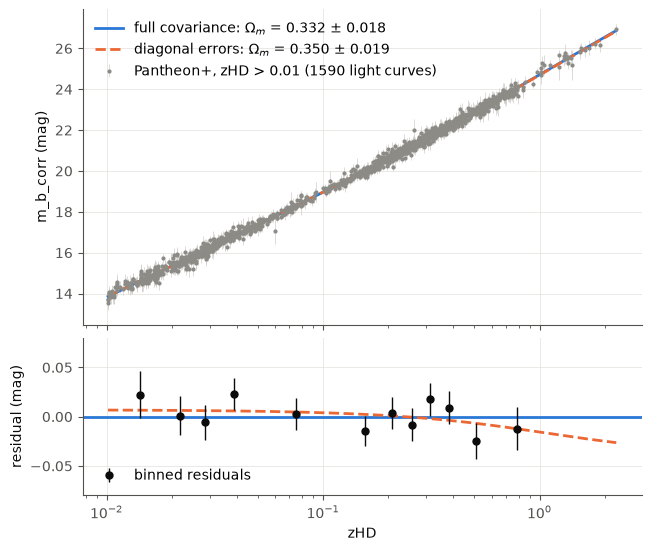

In [11]:
def plot_hubble_diagram():
    data = table[table.zHD > SPEC.z_min]
    z, z_hel, m, err = (data[c].to_numpy() for c in ("zHD", "zHEL", "m_b_corr", "m_b_corr_err_DIAG"))
    curve_z = np.geomspace(z.min(), z.max(), 400)

    def model(fit, zz, zz_hel):
        return distance_modulus(fit["omega_m"], zz, zz_hel, SPEC.H0) + fit["M"]

    fig, (top, bottom) = plt.subplots(2, 1, figsize=(6.4, 5.4), sharex=True, height_ratios=[2, 1],
                                      layout="constrained")
    top.errorbar(z, m, err, fmt="o", ms=2, color=MUTED, ecolor="#cfceca", elinewidth=0.5,
                 label=f"Pantheon+, zHD > {SPEC.z_min:g} ({len(z)} light curves)")
    top.plot(curve_z, model(REFERENCE, curve_z, curve_z), color=BLUE, lw=2,
             label=f"full covariance: $\\Omega_m$ = {REFERENCE['omega_m']:.3f} ± {REFERENCE['omega_m_err']:.3f}")
    top.plot(curve_z, model(REFERENCE_DIAG, curve_z, curve_z), color=ORANGE, lw=2, ls="--",
             label=f"diagonal errors: $\\Omega_m$ = {REFERENCE_DIAG['omega_m']:.3f} ± {REFERENCE_DIAG['omega_m_err']:.3f}")
    top.set_xscale("log")
    top.set_ylabel("m_b_corr (mag)")
    top.legend(loc="upper left")

    residual = m - model(REFERENCE, z, z_hel)
    edges = np.quantile(z, np.linspace(0, 1, 13))          # 12 bins with equal numbers of supernovae
    index = np.clip(np.digitize(z, edges) - 1, 0, 11)
    centres, means, errors = [], [], []
    for k in range(12):
        inside = index == k
        w = err[inside] ** -2
        centres.append(np.exp(np.mean(np.log(z[inside]))))
        means.append(np.sum(w * residual[inside]) / np.sum(w))
        errors.append(np.sum(w) ** -0.5)
    bottom.axhline(0, color=BLUE, lw=2)
    bottom.plot(curve_z, model(REFERENCE_DIAG, curve_z, curve_z) - model(REFERENCE, curve_z, curve_z),
                color=ORANGE, lw=2, ls="--")
    bottom.errorbar(centres, means, errors, fmt="o", ms=5, color=INK, elinewidth=1, label="binned residuals")
    bottom.set_ylim(-0.08, 0.08)
    bottom.set_xlabel("zHD")
    bottom.set_ylabel("residual (mag)")
    bottom.legend(loc="lower left")
    difference = model(REFERENCE_DIAG, z, z_hel) - model(REFERENCE, z, z_hel)
    print(f"Difference between the two models at the data: {difference.min():+.3f} to {difference.max():+.3f} mag; "
          f"median m_b_corr_err_DIAG: {np.median(err):.3f} mag")
    return fig


fig = plot_hubble_diagram()
save_figure(fig, "hubble_diagram")
plt.show()

The binned residuals are weighted with the diagonal errors and serve as a guide to the eye. Over the redshift range of the data the two models differ by at most 0.03 mag, much less than the median uncertainty of one supernova, 0.21 mag. $\Omega_m$ is constrained by the combination of the 1590 light curves, and the two fits combine them with different weights. Only the covariance matrix contains the correlations that systematic uncertainties introduce between supernovae.

### 1.4. Task statement and grading

Every agent in §2 and §3 receives the text printed by the next cell. It names the files, states the requirements of §1.2 and fixes the format of the result. A run is graded correct when the $\Omega_m$ that it reports lies within `TOLERANCE` = 0.005 of the reference value and its uncertainty within 0.005 of the reference uncertainty. The tolerance is about a quarter of the statistical uncertainty. It accepts the differences between numerical methods and the change of $(1+z)$ convention in the table above, and it rejects the fits with diagonal errors, with `zCMB` or without the redshift cut.

In [12]:
DATA_FILES = f'''Data
- Table: {TABLE_PATH}
  Whitespace-separated with one header row; columns include zHD, zHEL, zCMB, m_b_corr, m_b_corr_err_DIAG, RA, DEC.
- Covariance: {COV_PATH}
  Statistical plus systematic covariance of m_b_corr. The first line is N = 1701; the N*N entries follow,
  one per line, in row-major order; rows and columns follow the rows of the table.'''

TASK = f'''Measure the matter density Omega_m of a flat LCDM cosmology from the Pantheon+ type Ia supernovae.

{DATA_FILES}

Requirements
{SPEC.requirements()}'''
print(TASK)


def grade(omega_m, omega_m_err, reference=None):
    # Compare a reported Omega_m and uncertainty with a reference fit (by default the full sample).
    reference = reference or REFERENCE
    if omega_m is None:
        return "no result"
    if abs(omega_m - reference["omega_m"]) > TOLERANCE:
        return "wrong"
    if omega_m_err is None or abs(omega_m_err - reference["omega_m_err"]) > TOLERANCE:
        return "wrong error"
    return "correct"


def script_flags(scripts):
    # Read from the source of a run's scripts: does it open the covariance file, which redshift columns appear.
    source = "\n".join(scripts)
    return {"reads_cov_file": "STAT+SYS" in source,
            "z_columns": "+".join(c for c in ("zHD", "zCMB", "zHEL") if re.search(rf"\b{c}\b", source))}


def to_json(value):
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    if isinstance(value, np.bool_):
        return bool(value)
    if isinstance(value, BaseModel):
        return value.model_dump()
    return str(value)


def save_measurements():
    (RESULTS_DIR / "measurements.json").write_text(json.dumps(MEASUREMENTS, indent=1, default=to_json) + "\n")


MEASUREMENTS = {
    "meta": {
        "date_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "model": MODEL, "model_reported": MODEL_REPORTED, "versions": VERSIONS, "platform": platform.platform(),
        "settings": {"REPEATS": REPEATS, "EXEC_TIMEOUT": EXEC_TIMEOUT, "OUTPUT_LIMIT": OUTPUT_LIMIT,
                     "MAX_TURNS": MAX_TURNS, "MAX_ATTEMPTS": MAX_ATTEMPTS, "MAX_REWORK": MAX_REWORK,
                     "TOLERANCE": TOLERANCE},
    },
    "reference": {"full": REFERENCE, "diagonal": REFERENCE_DIAG,
                  "variants": variant_fits, "brout2022": {"omega_m": 0.334, "omega_m_err": 0.018}},
}
save_measurements()

Measure the matter density Omega_m of a flat LCDM cosmology from the Pantheon+ type Ia supernovae.

Data
- Table: <notebook folder>/data/Pantheon+SH0ES.dat
  Whitespace-separated with one header row; columns include zHD, zHEL, zCMB, m_b_corr, m_b_corr_err_DIAG, RA, DEC.
- Covariance: <notebook folder>/data/Pantheon+SH0ES_STAT+SYS.cov
  Statistical plus systematic covariance of m_b_corr. The first line is N = 1701; the N*N entries follow,
  one per line, in row-major order; rows and columns follow the rows of the table.

Requirements
1. Use the light curves (table rows) with zHD > 0.01.
2. Model: m_b_corr = 5 log10(d_L / Mpc) + 25 + M, with d_L = (1 + zHEL) D_C(zHD) and D_C the comoving distance of a flat LCDM cosmology with H0 = 70 km/s/Mpc.
3. M is a free offset: minimise chi^2 over M analytically at each Omega_m.
4. Weight the residuals with the full statistical and systematic covariance matrix, restricted to the rows and columns of the selected supernovae.
5. Report Omega_m, its 1-s

## 2. One agent with a code-execution tool

### 2.1. The agent loop

An agent in its simplest form is a loop around one model. The model receives the task and the description of a tool, here `run_python`, which runs a script and returns its exit code and printed output. When a reply requests a tool call, the loop runs the tool and appends its output to the conversation. When a reply contains no tool call, the loop stops and that reply is the answer. This loop is known as ReAct, for reasoning and acting.

In LangGraph the loop is a graph with two nodes, `agent` and `tools`. A conditional edge after `agent` chooses between `tools` and the end of the run; `MAX_TURNS` bounds the number of model calls. The printed edges show the structure, with `-.->` marking a conditional edge.

In [13]:
SINGLE_SYSTEM = f'''You are an astrophysicist who analyses data with Python.
Use the run_python tool to execute scripts. Each call starts a fresh Python process in a working directory that
keeps the files written by earlier calls. Available packages: numpy, scipy, pandas, matplotlib.
Scripts are stopped after {EXEC_TIMEOUT} s, and output beyond {OUTPUT_LIMIT} characters is shortened.
When the analysis is complete, reply with a short report whose last line is
FINAL {{"omega_m": <value>, "omega_m_err": <value>, "chi2_min": <value>, "n_sn": <value>, "covariance": "full" or "diagonal"}}'''


def make_single_agent(workdir, ledger):
    @tool
    def run_python(code: str) -> str:
        "Run a Python script in a fresh process and return its exit code and printed output."
        return run_code(code, workdir, ledger, "agent").report()

    model = llm.bind_tools([run_python])

    def agent(state: MessagesState):
        return {"messages": [ask(model, state["messages"], ledger, "agent")]}

    def tools(state: MessagesState):
        outputs = []
        for call in state["messages"][-1].tool_calls:
            try:
                content = run_python.invoke(call["args"])
            except Exception as error:      # malformed arguments are reported back to the model
                content = f"Tool error: {error}"
            outputs.append(ToolMessage(content, tool_call_id=call["id"]))
        return {"messages": outputs}

    def after_agent(state: MessagesState):
        if state["messages"][-1].tool_calls and len(ledger.calls) < MAX_TURNS:
            return "tools"
        return END

    graph = StateGraph(MessagesState)
    graph.add_node("agent", agent)
    graph.add_node("tools", tools)
    graph.add_edge(START, "agent")
    graph.add_conditional_edges("agent", after_agent, ["tools", END])
    graph.add_edge("tools", "agent")
    return graph.compile()


show_graph(make_single_agent(RUNS_DIR / "unused", Ledger("graph")))

   __start__ ---> agent
       agent -.-> __end__
       agent -.-> tools
       tools ---> agent


### 2.2. Repeated runs

The model samples its replies, so two runs of the same agent can write different scripts and make different choices. The next cell runs the agent `REPEATS` times. For each run, the table lists the model calls, the tokens, the script executions and the wall time; the $\Omega_m$ and uncertainty of the `FINAL` line and its grade; the covariance that the reply names; the number of light curves reported, which is 1590 with the cut at $z_\mathrm{HD} > 0.01$; and two properties read from the source of the scripts: whether they open the covariance file and which redshift columns they name.

In [14]:
def run_single_agent(i):
    ledger = Ledger(f"single-{i}")
    workdir = RUNS_DIR / f"single_{i}"
    graph = make_single_agent(workdir, ledger)
    state = graph.invoke({"messages": [SystemMessage(SINGLE_SYSTEM), HumanMessage(TASK)]},
                         {"recursion_limit": 4 * MAX_TURNS})
    totals = ledger.totals()
    final = parse_tagged(state["messages"][-1].text, "FINAL") or {}
    omega_m, omega_m_err = number(final.get("omega_m")), number(final.get("omega_m_err"))
    scripts = [p.read_text() for p in sorted(workdir.glob("script_*.py"))]
    return {"run": i, **totals, "omega_m": omega_m, "omega_m_err": omega_m_err,
            "grade": grade(omega_m, omega_m_err), "n_sn": final.get("n_sn"), "covariance_reported": final.get("covariance"),
            **script_flags(scripts), "answer": state["messages"][-1].text}


SINGLE = [run_single_agent(i) for i in range(1, REPEATS + 1)]
columns = ["run", "calls", "input_tokens", "output_tokens", "reasoning_tokens", "executions", "failed_executions",
           "wall_s", "omega_m", "omega_m_err", "grade", "n_sn", "covariance_reported", "reads_cov_file", "z_columns"]
display(pd.DataFrame(SINGLE)[columns])
print(f"{sum(r['grade'] == 'correct' for r in SINGLE)} of {len(SINGLE)} runs correct; "
      f"{sum(r['reads_cov_file'] for r in SINGLE)} of {len(SINGLE)} read the covariance file.")
print("\nFinal reply of run 1:\n" + clip(SINGLE[0]["answer"], 1500))
MEASUREMENTS["single_agent"] = SINGLE
save_measurements()

,run,calls,input_tokens,output_tokens,reasoning_tokens,executions,failed_executions,wall_s,omega_m,omega_m_err,grade,n_sn,covariance_reported,reads_cov_file,z_columns
0,1,3,5944,2564,0,2,1,9.8,0.331600,0.018200,correct,1590,full,True,zHD+zHEL
1,2,4,8249,2395,0,3,1,14.4,0.331600,0.018200,correct,1590,full,True,zHD+zHEL
2,3,5,12402,2591,0,4,2,12.3,0.331600,0.018200,correct,1590,full,True,zHD+zHEL
3,4,3,5405,2286,0,2,1,10.0,0.331574,0.018195,correct,1590,full,True,zHD+zHEL
4,5,4,8258,1912,0,3,1,11.2,0.331600,0.018200,correct,1590,full,True,zHD+zHEL


5 of 5 runs correct; 5 of 5 read the covariance file.

Final reply of run 1:
The matter density $\Omega_m$ of a flat $\Lambda$CDM cosmology was determined by analyzing the Pantheon+ type Ia supernovae dataset, applying the specified filters and covariance matrix. Using supernovae with $z_{HD} > 0.01$ (a total of 1590 light curves), the best-fit parameters were found by minimizing the $\chi^2$ statistic, which accounts for both statistical and systematic uncertainties through the provided full covariance matrix. The nuisance parameter $M$ was marginalized analytically at each $\Omega_m$ evaluation.

The analysis yielded:
*   $\Omega_m = 0.3316$
*   $\sigma_{\Omega_m} = 0.0182$
*   $\chi^2_{min} = 1402.9$
*   Number of supernovae used: 1590

FINAL {"omega_m": 0.3316, "omega_m_err": 0.0182, "chi2_min": 1402.9, "n_sn": 1590, "covariance": "full"}


A failed execution is a script that raised an exception or exceeded the time limit. The tool output then contains the traceback, and the model's next reply can correct the script. Recovery from an error therefore takes place inside the conversation, without a separate step. Every call resends the whole conversation, including the earlier scripts and their outputs, so the input tokens of a run grow with each turn. §7 lists the causes of the failed executions.

## 3. Planning and control

### 3.1. Planner, controller and specialists

CMBAgent, and its LangGraph port cmbagent_lg, separate planning from execution. A planner writes the plan once, as a structured object: a list of steps, each assigned to one agent and described by bullet points. A controller then executes the steps in order. It passes each agent the task, its step and the outputs of the earlier steps.

The version below is a minimal implementation of the pattern, written for this notebook. It has three specialists and none of the additional checks of cmbagent_lg; the companion notebook, lecture01_cmbagent_lg.ipynb, runs the same task through cmbagent_lg itself.

- The **engineer** writes one script for its step. The executor runs it. After an error, the engineer receives its script and the traceback and writes a corrected script, at most `MAX_ATTEMPTS` times in total. This is the self-debugging loop of cmbagent_lg.
- The **reviewer** compares the scripts and their outputs with the requirements of the task. It approves the result or returns a list of issues to the last engineering step, at most `MAX_REWORK` times.
- The **writer** reports the result from the printed outputs.

The plan is a Pydantic object, so the planner's reply is parsed and validated before any step runs. The controller also enforces the shape of the plan: engineering steps (at most three), one review step, then one writing step. A plan of another shape is reordered before execution, and the run records that it was.

In [15]:
class Step(BaseModel):
    agent: Literal["engineer", "reviewer", "writer"]
    goal: str = Field(description="What the step produces")
    bullet_points: list[str] = Field(description="Two to five concrete instructions")


class Plan(BaseModel):
    steps: list[Step]


class Review(BaseModel):
    approved: bool = Field(description="True only if every requirement is met and the printed output supports the result")
    issues: list[str] = Field(description="Concrete problems for the engineer to fix; empty when approved")


class Report(BaseModel):
    text: str = Field(description="Results paragraph that quotes the printed numbers")
    omega_m: float
    omega_m_err: float
    chi2_min: float
    n_sn: int = Field(description="Number of light curves (table rows) used")
    covariance: Literal["full", "diagonal"]


PLANNER_SYSTEM = '''You plan data analyses for a team of three agents.
- engineer: writes one Python script per step; scripts run in a shared working directory, so a step can read
  files written by earlier steps.
- reviewer: checks the engineering results against the requirements of the task, reading the scripts and their output.
- writer: reports the final result with the numbers printed by the scripts.
Write a plan of three or four steps: one or two engineer steps, one reviewer step, then one writer step.'''

ENGINEER_SYSTEM = f'''You write Python scripts for data analysis. Reply with one complete script in a single ```python block.
The script runs as `python script.py` in a fresh process, in a working directory that keeps the files written by
earlier scripts. Available packages: numpy, scipy, pandas, matplotlib. Scripts are stopped after {EXEC_TIMEOUT} s.
Print the numbers that the step produces. If the script computes Omega_m, its last printed line must be
RESULT {{"omega_m": <value>, "omega_m_err": <value>, "chi2_min": <value>, "n_sn": <value>}}'''

REVIEWER_SYSTEM = '''You review data analyses. Compare the scripts and their printed output with each requirement of
the task. Approve only if every requirement is met and the printed output supports the result. Otherwise list
concrete issues that the engineer can fix.'''

REPORT_SYSTEM = '''You report the result of a data analysis. Quote only numbers that appear in the printed outputs,
and state which covariance the fit used.'''


def describe(plan):
    return "\n".join(f"{k}. [{s.agent}] {s.goal}" + "".join(f"\n   - {b}" for b in s.bullet_points)
                     for k, s in enumerate(plan.steps, 1))


def normalise(plan):
    # Controller rule: engineer steps (at most three), then one reviewer step, then one writer step.
    by_agent = {a: [s for s in plan.steps if s.agent == a] for a in ("engineer", "reviewer", "writer")}
    steps = by_agent["engineer"][:3] or [Step(agent="engineer", goal="Carry out the analysis", bullet_points=[])]
    steps.append((by_agent["reviewer"] or [Step(agent="reviewer", goal="Check the result", bullet_points=[])])[0])
    steps.append((by_agent["writer"] or [Step(agent="writer", goal="Report the result", bullet_points=[])])[-1])
    return Plan(steps=steps)

In [16]:
class PlanState(TypedDict, total=False):
    plan: Plan
    reordered: bool          # the controller changed the shape of the plan
    index: int               # current step
    attempts: int            # engineer attempts at the current step
    reworks: int             # results sent back by the reviewer
    code: str
    feedback: str            # traceback or reviewer issues for the next engineer attempt
    results: dict            # step index -> goal, code, output, ok
    review: Review
    reviews: list
    send_back: bool
    report: Report


def make_planning_control(workdir, ledger):
    def planner(state):
        plan = ask_structured(Plan, [SystemMessage(PLANNER_SYSTEM), HumanMessage(TASK)], ledger, "planner")
        shaped = normalise(plan)
        return {"plan": shaped, "reordered": [s.agent for s in plan.steps] != [s.agent for s in shaped.steps],
                "index": -1, "results": {}, "reworks": 0, "reviews": []}

    def controller(state):
        return {"index": state["index"] + 1, "attempts": 0, "feedback": ""}

    def next_step(state):
        if state["index"] >= len(state["plan"].steps):
            return END
        return state["plan"].steps[state["index"]].agent

    def outputs(state, with_code):
        parts = []
        for k, result in sorted(state["results"].items()):
            script = f"Script:\n```python\n{result['code']}\n```\n" if with_code else ""
            parts.append(f"Step {k + 1} ({result['goal']}):\n{script}Output:\n{result['output']}")
        return "\n\n".join(parts) or "none"

    def engineer(state):
        i, step = state["index"], state["plan"].steps[state["index"]]
        earlier = {k: r for k, r in state["results"].items() if k < i}
        files = sorted(p.name for p in workdir.glob("*") if not p.name.startswith(("script_", ".")))
        prompt = (f"{TASK}\n\nPlan:\n{describe(state['plan'])}\n\nCurrent step {i + 1}: {step.goal}\n"
                  + "\n".join(f"- {b}" for b in step.bullet_points)
                  + f"\n\nFiles in the working directory: {', '.join(files) or 'none'}\n\n"
                  + f"Outputs of earlier steps:\n{outputs({'results': earlier}, with_code=False)}\n\n{state['feedback']}")
        reply = ask(llm, [SystemMessage(ENGINEER_SYSTEM), HumanMessage(prompt)], ledger, "engineer")
        return {"code": extract_code(reply.text), "attempts": state["attempts"] + 1}

    def executor(state):
        i, step = state["index"], state["plan"].steps[state["index"]]
        run = run_code(state["code"], workdir, ledger, "executor")
        results = dict(state["results"])
        results[i] = {"goal": step.goal, "code": state["code"], "output": run.report(), "ok": run.ok}
        feedback = "" if run.ok else (f"Your previous script for this step failed:\n```python\n{state['code']}\n```\n"
                                      f"{run.report()}\nReply with a corrected complete script.")
        return {"results": results, "feedback": feedback}

    def after_executor(state):
        failed = not state["results"][state["index"]]["ok"]
        return "engineer" if failed and state["attempts"] < MAX_ATTEMPTS else "controller"

    def reviewer(state):
        i, step = state["index"], state["plan"].steps[state["index"]]
        prompt = (f"{TASK}\n\nReview step: {step.goal}\n" + "\n".join(f"- {b}" for b in step.bullet_points)
                  + f"\n\n{outputs(state, with_code=True)}")
        review = ask_structured(Review, [SystemMessage(REVIEWER_SYSTEM), HumanMessage(prompt)], ledger, "reviewer")
        update = {"review": review, "reviews": state["reviews"] + [review.model_dump()], "send_back": False}
        engineering = [k for k in range(i) if state["plan"].steps[k].agent == "engineer"]
        if not review.approved and state["reworks"] < MAX_REWORK and engineering:
            last = engineering[-1]
            issues = "\n".join(f"- {issue}" for issue in review.issues)
            update |= {"index": last, "attempts": 0, "reworks": state["reworks"] + 1, "send_back": True,
                       "feedback": f"The reviewer returned these issues:\n{issues}\nYour previous script for this step:\n"
                                   f"```python\n{state['results'][last]['code']}\n```\nReply with a corrected complete script."}
        return update

    def after_reviewer(state):
        return "engineer" if state["send_back"] else "controller"

    def writer(state):
        step = state["plan"].steps[state["index"]]
        review = state.get("review")
        verdict = "approved" if review and review.approved else "not approved: " + "; ".join(review.issues if review else [])
        prompt = (f"{TASK}\n\nWriter step: {step.goal}\n" + "\n".join(f"- {b}" for b in step.bullet_points)
                  + f"\n\nPrinted outputs:\n{outputs(state, with_code=False)}\n\nReview: {verdict}")
        return {"report": ask_structured(Report, [SystemMessage(REPORT_SYSTEM), HumanMessage(prompt)], ledger, "writer")}

    graph = StateGraph(PlanState)
    for name, node in [("planner", planner), ("controller", controller), ("engineer", engineer),
                       ("executor", executor), ("reviewer", reviewer), ("writer", writer)]:
        graph.add_node(name, node)
    graph.add_edge(START, "planner")
    graph.add_edge("planner", "controller")
    graph.add_conditional_edges("controller", next_step, ["engineer", "reviewer", "writer", END])
    graph.add_edge("engineer", "executor")
    graph.add_conditional_edges("executor", after_executor, ["engineer", "controller"])
    graph.add_conditional_edges("reviewer", after_reviewer, ["engineer", "controller"])
    graph.add_edge("writer", "controller")
    return graph.compile()


show_graph(make_planning_control(RUNS_DIR / "unused", Ledger("graph")))

   __start__ ---> planner
  controller -.-> __end__
  controller -.-> engineer
  controller -.-> reviewer
  controller -.-> writer
    engineer ---> executor
    executor -.-> controller
    executor -.-> engineer
     planner ---> controller
    reviewer -.-> controller
    reviewer -.-> engineer
      writer ---> controller


### 3.2. Repeated runs

The table has the columns of §2.2, with the calls split by agent (planner P, engineer E, reviewer R, writer W), the number of results sent back by the reviewer and its last verdict. Two values of $\Omega_m$ are graded: the one in the writer's report, which is what the system returns, and the one on the `RESULT` line printed by the last engineering script. The column `report_matches_printed` states whether the two agree. The `Report` schema requires numeric fields, so the writer returns numbers even when the review was not approved or no script printed a result.

In [17]:
def run_planning_control(i):
    ledger = Ledger(f"plan-{i}")
    workdir = RUNS_DIR / f"plan_{i}"
    state = make_planning_control(workdir, ledger).invoke({}, {"recursion_limit": 100})
    totals = ledger.totals()
    report = state.get("report")
    engineering = [r for k, r in sorted(state["results"].items()) if state["plan"].steps[k].agent == "engineer"]
    printed = (parse_tagged(engineering[-1]["output"], "RESULT") or {}) if engineering else {}
    by_agent = Counter(c["agent"] for c in ledger.calls)
    omega_m = report.omega_m if report else None
    omega_m_err = report.omega_m_err if report else None
    return {"run": i, **totals,
            "calls_by_agent": " ".join(f"{a[0].upper()}{by_agent[a]}" for a in ("planner", "engineer", "reviewer", "writer")),
            "reworks": state["reworks"], "approved": state["review"].approved if state.get("review") else None,
            "omega_m": omega_m, "omega_m_err": omega_m_err, "grade": grade(omega_m, omega_m_err),
            "n_sn": report.n_sn if report else None, "covariance_reported": report.covariance if report else None,
            "omega_m_printed": number(printed.get("omega_m")),
            "grade_printed": grade(number(printed.get("omega_m")), number(printed.get("omega_m_err"))),
            "report_matches_printed": omega_m is not None and number(printed.get("omega_m")) is not None
                                      and abs(omega_m - number(printed.get("omega_m"))) < 5e-4,
            **script_flags([r["code"] for r in engineering]),
            "reordered": state["reordered"], "plan": state["plan"].model_dump(), "reviews": state["reviews"],
            "report": report.text if report else None}


PLANNED = [run_planning_control(i) for i in range(1, REPEATS + 1)]
columns = ["run", "calls", "calls_by_agent", "input_tokens", "output_tokens", "executions", "failed_executions",
           "reworks", "approved", "wall_s", "omega_m", "omega_m_err", "grade", "n_sn", "omega_m_printed",
           "grade_printed", "report_matches_printed", "reads_cov_file", "z_columns"]
display(pd.DataFrame(PLANNED)[columns])
print(f"{sum(r['grade'] == 'correct' for r in PLANNED)} of {len(PLANNED)} reports correct; "
      f"{sum(r['report_matches_printed'] for r in PLANNED)} quote the Omega_m printed by the last engineering script; "
      f"plans reordered by the controller: {sum(r['reordered'] for r in PLANNED)}")
print("\nPlan of run 1:\n" + describe(Plan(**PLANNED[0]["plan"])))
for r in PLANNED:
    for k, review in enumerate(r["reviews"], 1):
        print(f"\nRun {r['run']}, review {k}: approved = {review['approved']}"
              + "".join(f"\n  - {issue}" for issue in review["issues"]))
print("\nReport of run 1:\n" + (PLANNED[0]["report"] or "none"))
MEASUREMENTS["planning_control"] = PLANNED
save_measurements()

,run,calls,calls_by_agent,input_tokens,output_tokens,executions,failed_executions,reworks,approved,wall_s,omega_m,omega_m_err,grade,n_sn,omega_m_printed,grade_printed,report_matches_printed,reads_cov_file,z_columns
0,1,6,P1 E3 R1 W1,9315,3398,3,1,0,True,18.4,0.3316,0.0182,correct,1590,0.3316,correct,True,True,zHD+zHEL
1,2,4,P1 E1 R1 W1,3900,1435,1,0,0,True,9.9,0.3316,0.0187,correct,1590,0.3316,correct,True,True,zHD+zHEL
2,3,11,P1 E7 R2 W1,22746,8149,7,5,1,False,33.0,0.3524,0.0001,wrong,1590,NaN,no result,False,True,zHD+zHEL
3,4,6,P1 E2 R2 W1,8344,3183,2,0,1,False,17.9,0.3316,0.0182,correct,1590,0.3316,correct,True,True,zHD+zHEL
4,5,4,P1 E1 R1 W1,3828,1552,1,0,0,True,10.7,0.3286,0.0245,wrong error,1590,0.3286,wrong error,True,True,zHD+zHEL


3 of 5 reports correct; 4 quote the Omega_m printed by the last engineering script; plans reordered by the controller: 0

Plan of run 1:
1. [engineer] Load data, select sample, and define the chi-squared function.
   - Load the Pantheon+SH0ES.dat file and the covariance matrix.
   - Filter the dataset to include only supernovae with zHD > 0.01.
   - Subset the covariance matrix to correspond to the rows of the selected supernovae.
   - Implement a function to calculate the comoving distance D_C for a flat LCDM cosmology with H0=70.
2. [engineer] Perform parameter estimation for Omega_m.
   - Define the chi-squared objective function as a function of Omega_m, incorporating the analytical minimization of the absolute magnitude offset M.
   - Use a minimization routine or grid search to find the best-fit Omega_m and the minimum chi-squared value.
   - Calculate the 1-sigma uncertainty by finding the range where Delta chi^2 equals 1.
   - Save the results (Omega_m, uncertainty, min_chi2, a

Compare the calls, tokens and wall time with §2.2. The planner, each engineering attempt, each review and the report are separate model calls, and each of their prompts contains the task. An engineer's prompt holds the outputs of the earlier steps and the last traceback, while the single agent resends its whole conversation at every turn. Which effect dominates the bill depends on the number of attempts and turns that a run needs. The two tables give the numbers for this task.

## 4. Fan-out over sky quadrants

### 4.1. Orchestrator and workers

An orchestrator–workers graph divides a task into independent parts, runs one worker per part and combines the results in an aggregator. Here the parts are four quadrants of right ascension: [0°, 90°), [90°, 180°), [180°, 270°) and [270°, 360°). Comparing $\Omega_m$ between quadrants is a simple test of isotropy. A difference could also come from a systematic error that depends on the survey footprints. The next cell gives the number of light curves N and the reference fit of each quadrant, with the conventions of §1.2. The workers do not see these values.

In [18]:
QUADRANTS = [(0, 90), (90, 180), (180, 270), (270, 360)]


def in_quadrant(quadrant):
    lo, hi = quadrant
    return ((table.RA >= lo) & (table.RA < hi)).to_numpy()


QUADRANT_REFERENCE = {q: reference_fit(SPEC, in_quadrant(q)) for q in QUADRANTS}
display(pd.DataFrame([{"RA (deg)": f"[{lo}, {hi})", "N": fit["n_sn"], "Omega_m": round(fit["omega_m"], 4),
                       "sigma": round(fit["omega_m_err"], 4), "chi2_min": round(fit["chi2_min"], 1)}
                      for (lo, hi), fit in QUADRANT_REFERENCE.items()]))

,RA (deg),N,Omega_m,sigma,chi2_min
0,"[0, 90)",648,0.3462,0.0271,530.3
1,"[90, 180)",280,0.3063,0.0362,200.3
2,"[180, 270)",299,0.3271,0.0301,285.5
3,"[270, 360)",363,0.3448,0.0403,360.8


LangGraph's `Send` starts one worker per quadrant from a single conditional edge, and the workers of one step run concurrently in threads. With the configuration option `max_concurrency=1`, the same graph runs one worker at a time, which gives a sequential baseline with identical prompts.

Each worker runs the engineer–executor loop of §3 as one function, `solve`. Its brief names the quadrant, the files and the result line, and it does not repeat the requirements of §1.2. Here the brief is fixed text, so that the runs of §4 and §5 differ only in the text added to the brief. An orchestrator model that writes its own briefs can omit them in the same way. §5 measures the consequence.

The aggregator is ordinary code. It computes the inverse-variance weighted mean of the four values and the $\chi^2$ of the values about the mean. The mean ignores the correlations between quadrants that the systematic covariance introduces. It serves as a consistency check, and the fit of §1.3 remains the measurement of $\Omega_m$.

In [19]:
BRIEF = '''Measure the matter density Omega_m of a flat LCDM cosmology from the Pantheon+ type Ia supernovae
with right ascension RA in [{lo}, {hi}) degrees.

{data}
{conventions}
Report Omega_m with its 1-sigma uncertainty and the number of light curves (table rows) used.'''


def solve(brief, workdir, ledger, agent):
    # Engineer-executor loop as one function: write a script, run it, fix it, at most MAX_ATTEMPTS times.
    feedback, outcomes = "", []
    for attempt in range(1, MAX_ATTEMPTS + 1):
        reply = ask(llm, [SystemMessage(ENGINEER_SYSTEM), HumanMessage(brief + feedback)], ledger, agent)
        code = extract_code(reply.text)
        run = run_code(code, workdir, ledger, agent)
        result = parse_tagged(run.stdout, "RESULT")
        outcomes.append("RESULT printed" if run.ok and result else "no RESULT line" if run.ok
                        else (run.stderr.strip().splitlines() or ["no message"])[-1][:160])
        if run.ok and result:
            break
        feedback = (f"\n\nYour previous script:\n```python\n{code}\n```\n{run.report()}\n"
                    "It failed or did not print the RESULT line. Reply with a corrected complete script.")
    return {"ok": bool(run.ok and result), "attempts": attempt, "outcomes": outcomes, "code": code,
            "output": run.report(), "result": result or {}}


def usable(result):
    return number(result.get("omega_m")) is not None and (number(result.get("omega_m_err")) or 0) > 0


def combine(results):
    # Inverse-variance weighted mean of per-quadrant values, and the chi^2 of the values about it.
    values = np.array([number(r["omega_m"]) for r in results])
    weights = np.array([number(r["omega_m_err"]) for r in results]) ** -2.0
    mean = np.sum(weights * values) / np.sum(weights)
    chi2, dof = float(np.sum(weights * (values - mean) ** 2)), len(values) - 1
    return {"omega_m": float(mean), "omega_m_err": float(np.sum(weights) ** -0.5), "chi2": chi2, "dof": dof,
            "p_value": float(chi2_distribution.sf(chi2, dof))}


class FanOutState(TypedDict):
    conventions: str
    results: Annotated[list, operator.add]   # each worker appends one result
    combined: dict


def make_fan_out(root, ledger):
    def dispatch(state):
        return [Send("worker", {"quadrant": q, "conventions": state["conventions"]}) for q in QUADRANTS]

    def worker(task):
        lo, hi = task["quadrant"]
        brief = BRIEF.format(lo=lo, hi=hi, data=DATA_FILES, conventions=task["conventions"])
        return {"results": [{"quadrant": (lo, hi), **solve(brief, root / f"ra_{lo:03d}", ledger, f"RA {lo}-{hi}")}]}

    def aggregate(state):
        valid = [r["result"] for r in state["results"] if r["ok"] and usable(r["result"])]
        return {"combined": combine(valid) if len(valid) > 1 else {}}

    graph = StateGraph(FanOutState)
    graph.add_node("worker", worker)
    graph.add_node("aggregate", aggregate)
    graph.add_conditional_edges(START, dispatch, ["worker"])
    graph.add_edge("worker", "aggregate")
    graph.add_edge("aggregate", END)
    return graph.compile()


def run_fan_out(name, conventions="", max_concurrency=None):
    ledger = Ledger(name)
    config = {"max_concurrency": max_concurrency} if max_concurrency else {}
    state = make_fan_out(RUNS_DIR / name, ledger).invoke({"conventions": conventions, "results": []}, config)
    return {"name": name, **ledger.totals(), "results": sorted(state["results"], key=lambda r: r["quadrant"]),
            "combined": state["combined"], "call_log": ledger.calls, "execution_log": ledger.executions}


show_graph(make_fan_out(RUNS_DIR / "unused", Ledger("graph")))

   __start__ -.-> worker
      worker ---> aggregate
   aggregate ---> __end__


### 4.2. Parallel and sequential runs

The next cell runs the graph twice with the same briefs: once with concurrent workers and once with `max_concurrency=1`. The table compares their bills; the figure shows when each model call and each script ran.

,parallel,sequential
calls,7.0,8.0
input_tokens,7113.0,11019.0
output_tokens,6520.0,7656.0
executions,7.0,8.0
failed_executions,4.0,5.0
wall_s,11.2,35.0


The sequential run took 3.1 times as long as the parallel run; its tokens were 1.37 times those of the parallel run.


,run,RA,attempts,Omega_m,sigma,N,reference,sigma reference,N reference,grade,reads_cov_file,z_columns
0,fan_parallel,0-90,1,0.388400,0.020200,672.0,0.3462,0.0271,648,wrong,True,zCMB
1,fan_parallel,90-180,2,0.403500,0.025900,306.0,0.3063,0.0362,280,wrong,True,zCMB
2,fan_parallel,180-270,3,NaN,NaN,NaN,0.3271,0.0301,299,no result,True,zCMB
3,fan_parallel,270-360,1,0.390000,0.042800,372.0,0.3448,0.0403,363,wrong,True,zCMB
4,fan_sequential,0-90,2,0.388361,0.028494,672.0,0.3462,0.0271,648,wrong,True,zCMB
5,fan_sequential,90-180,3,NaN,NaN,NaN,0.3063,0.0362,280,no result,True,zCMB
6,fan_sequential,180-270,1,0.335453,0.020807,351.0,0.3271,0.0301,299,wrong,True,zCMB
7,fan_sequential,270-360,2,0.345700,0.040200,372.0,0.3448,0.0403,363,correct,True,zHD


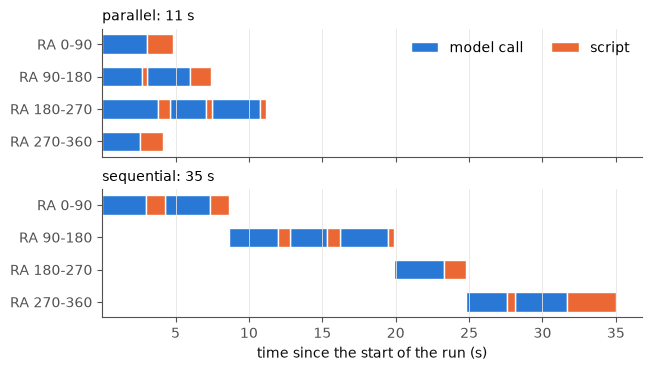

In [20]:
FAN = {"parallel": run_fan_out("fan_parallel"), "sequential": run_fan_out("fan_sequential", max_concurrency=1)}

keys = ["calls", "input_tokens", "output_tokens", "executions", "failed_executions", "wall_s"]
display(pd.DataFrame({mode: {k: run[k] for k in keys} for mode, run in FAN.items()}))
speedup = FAN["sequential"]["wall_s"] / FAN["parallel"]["wall_s"]
tokens = {mode: run["input_tokens"] + run["output_tokens"] for mode, run in FAN.items()}
print(f"The sequential run took {speedup:.1f} times as long as the parallel run; "
      f"its tokens were {tokens['sequential'] / tokens['parallel']:.2f} times those of the parallel run.")


def fan_out_table(run):
    rows = []
    for r in run["results"]:
        quadrant, result = tuple(r["quadrant"]), r["result"]
        omega_m, sigma = number(result.get("omega_m")), number(result.get("omega_m_err"))
        reference = QUADRANT_REFERENCE[quadrant]
        rows.append({"run": run["name"], "RA": f"{quadrant[0]}-{quadrant[1]}", "attempts": r["attempts"],
                     "Omega_m": omega_m, "sigma": sigma, "N": result.get("n_sn"),
                     "reference": round(reference["omega_m"], 4), "sigma reference": round(reference["omega_m_err"], 4),
                     "N reference": reference["n_sn"], "grade": grade(omega_m, sigma, reference),
                     **script_flags([r["code"]])})
    return rows


display(pd.DataFrame(fan_out_table(FAN["parallel"]) + fan_out_table(FAN["sequential"])))


def plot_timeline():
    fig, axes = plt.subplots(2, 1, figsize=(6.4, 3.6), sharex=True, layout="constrained")
    labels = [f"RA {lo}-{hi}" for lo, hi in QUADRANTS]
    for ax, (mode, run) in zip(axes, FAN.items()):
        for log, colour, kind in [(run["call_log"], BLUE, "model call"), (run["execution_log"], ORANGE, "script")]:
            for entry in log:
                ax.barh(labels.index(entry["agent"]), entry["t1"] - entry["t0"], left=entry["t0"], height=0.6,
                        color=colour, edgecolor="white", linewidth=1, label=kind)
        ax.set_yticks(range(len(labels)), labels)
        ax.invert_yaxis()
        ax.grid(axis="y", visible=False)
        ax.set_title(f"{mode}: {run['wall_s']:.0f} s", loc="left")
    handles, names = axes[0].get_legend_handles_labels()
    unique = dict(zip(names, handles))
    axes[0].legend(unique.values(), unique.keys(), loc="upper right", ncols=2)
    axes[1].set_xlabel("time since the start of the run (s)")
    return fig


fig = plot_timeline()
save_figure(fig, "fanout_timeline")
plt.show()
MEASUREMENTS["fan_out"] = {mode: {k: v for k, v in run.items()} for mode, run in FAN.items()}
MEASUREMENTS["fan_out"]["speedup"] = speedup
MEASUREMENTS["quadrant_reference"] = {f"{lo}-{hi}": fit for (lo, hi), fit in QUADRANT_REFERENCE.items()}
save_measurements()

Concurrency changes the wall time and leaves the work unchanged. The two runs start from the same prompts, so their token counts differ through the replies that the model samples and the number of attempts that each worker needs. The wall time of the parallel run is set by its slowest worker.

## 5. Context isolation

### 5.1. Conventions chosen by the workers

A worker sees only its brief. The requirements of §1.2 were part of the task in §2 and §3, but the fan-out brief carried only the quadrant, the files and the result line, so each worker chose its own conventions. The next cell repeats the deterministic fit of each quadrant with the alternative conventions of §1.3, which shows how far each choice moves $\Omega_m$ there. The table of §4.2 compares each worker's value with the reference of its quadrant and lists what its script did: the number of light curves, which shows whether the cut at 0.01 was applied, whether the script opens the covariance file and which redshift columns it names. A result is graded as in §1.4, against the reference fit of its quadrant.

In [21]:
quadrant_variants = {name: {f"{lo}-{hi}": round(reference_fit(spec, in_quadrant((lo, hi)))["omega_m"], 4)
                            for lo, hi in QUADRANTS} for name, spec in VARIANTS.items()}
display(pd.DataFrame(quadrant_variants).T)

brief_only = fan_out_table(FAN["parallel"]) + fan_out_table(FAN["sequential"])


def isolation_summary(label, rows):
    print(f"{label}: {sum(r['grade'] == 'correct' for r in rows)} of {len(rows)} worker results correct for their "
          f"quadrant; {sum(r['N'] == r['N reference'] for r in rows)} with the number of light curves of the cut at 0.01; "
          f"{sum(r['reads_cov_file'] for r in rows)} scripts open the covariance file; "
          f"{sum('zCMB' in r['z_columns'] for r in rows)} name zCMB.")


isolation_summary("Brief only", brief_only)

,0-90,90-180,180-270,270-360
reference,0.3462,0.3063,0.3271,0.3448
diagonal errors,0.3716,0.3045,0.3317,0.3646
zCMB in place of zHD,0.3752,0.3177,0.3256,0.3827
(1 + zHD) in place of (1 + zHEL),0.3459,0.3064,0.3265,0.3436
no redshift cut,0.3545,0.3716,0.3490,0.3470


Brief only: 1 of 8 worker results correct for their quadrant; 0 with the number of light curves of the cut at 0.01; 8 scripts open the covariance file; 7 name zCMB.


### 5.2. The documentation of the data release in the brief

The data release comes with a README that defines every column and states, in capitals, that `m_b_corr_err_DIAG` must not be used to fit cosmological parameters. An orchestrator could forward such documentation to its workers in place of a specification. The README does not state a redshift cut: the cut at 0.01 is a choice of the cosmological analysis of Brout et al. (2022). The next cell adds the full README text to each brief, through the `conventions` field of the graph state, and runs the parallel graph twice.

In [22]:
README_BLOCK = "\nDocumentation of the data release (README):\n" + README_TEXT + "\n"
WITH_README = [run_fan_out(f"fan_readme_{i}", README_BLOCK) for i in (1, 2)]
with_readme = [row for run in WITH_README for row in fan_out_table(run)]
display(pd.DataFrame(with_readme))
isolation_summary("Brief and README", with_readme)

,run,RA,attempts,Omega_m,sigma,N,reference,sigma reference,N reference,grade,reads_cov_file,z_columns
0,fan_readme_1,0-90,2,0.0500,0.0000,672.0,0.3462,0.0271,648,wrong,True,zHD
1,fan_readme_1,90-180,1,0.4035,0.0259,306.0,0.3063,0.0362,280,wrong,True,zCMB
2,fan_readme_1,180-270,1,0.3484,0.0305,351.0,0.3271,0.0301,299,wrong,True,zHD
3,fan_readme_1,270-360,2,0.3457,0.0248,372.0,0.3448,0.0403,363,wrong error,True,zHD
4,fan_readme_2,0-90,2,0.3331,0.0130,672.0,0.3462,0.0271,648,wrong,True,zHD
5,fan_readme_2,90-180,2,0.4035,0.0398,306.0,0.3063,0.0362,280,wrong,True,zCMB
6,fan_readme_2,180-270,3,NaN,NaN,NaN,0.3271,0.0301,299,no result,True,zHD
7,fan_readme_2,270-360,3,NaN,NaN,NaN,0.3448,0.0403,363,no result,True,zHD


Brief and README: 0 of 8 worker results correct for their quadrant; 0 with the number of light curves of the cut at 0.01; 8 scripts open the covariance file; 2 name zCMB.


### 5.3. Conventions in the shared state

The remedy is to make the conventions part of the state that the orchestrator passes to every worker. The `AnalysisSpec` object of §1.2 already holds them. Its requirements text goes into the `conventions` field of the graph state, which `dispatch` copies into each `Send`. The graph and the prompts are otherwise those of §4. The cell runs the parallel graph twice and plots the three arms of the experiment.

,run,RA,attempts,Omega_m,sigma,N,reference,sigma reference,N reference,grade,reads_cov_file,z_columns
0,fan_spec_1,0-90,2,0.346200,0.027100,648,0.3462,0.0271,648,correct,True,zHD+zHEL
1,fan_spec_1,90-180,1,0.306306,0.036196,280,0.3063,0.0362,280,correct,True,zHD+zHEL
2,fan_spec_1,180-270,1,0.327100,0.030100,299,0.3271,0.0301,299,correct,True,zHD+zHEL
3,fan_spec_1,270-360,1,0.344800,0.100000,363,0.3448,0.0403,363,wrong error,True,zHD+zHEL
4,fan_spec_2,0-90,1,0.346200,0.027100,648,0.3462,0.0271,648,correct,True,zHD+zHEL
5,fan_spec_2,90-180,2,0.306300,0.036200,280,0.3063,0.0362,280,correct,True,zHD+zHEL
6,fan_spec_2,180-270,1,0.327100,0.030100,299,0.3271,0.0301,299,correct,True,zHD+zHEL
7,fan_spec_2,270-360,1,0.344800,0.040300,363,0.3448,0.0403,363,correct,True,zHD+zHEL


Brief only: 1 of 8 worker results correct for their quadrant; 0 with the number of light curves of the cut at 0.01; 8 scripts open the covariance file; 7 name zCMB.
Brief and README: 0 of 8 worker results correct for their quadrant; 0 with the number of light curves of the cut at 0.01; 8 scripts open the covariance file; 2 name zCMB.
Brief and spec: 7 of 8 worker results correct for their quadrant; 8 with the number of light curves of the cut at 0.01; 8 scripts open the covariance file; 0 name zCMB.


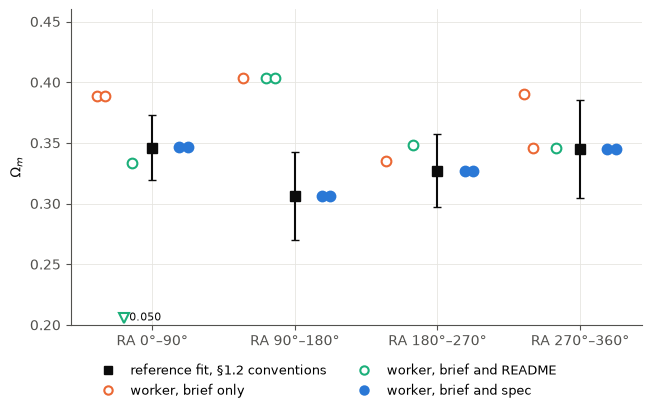

In [23]:
CONVENTIONS = "\nRequirements\n" + SPEC.requirements() + "\n"
WITH_SPEC = [run_fan_out(f"fan_spec_{i}", CONVENTIONS) for i in (1, 2)]
with_spec = [row for run in WITH_SPEC for row in fan_out_table(run)]
display(pd.DataFrame(with_spec))
for label, rows in [("Brief only", brief_only), ("Brief and README", with_readme), ("Brief and spec", with_spec)]:
    isolation_summary(label, rows)


def plot_isolation(low=0.20, high=0.46):
    fig, ax = plt.subplots(figsize=(6.4, 4.0), layout="constrained")
    names = [f"{lo}-{hi}" for lo, hi in QUADRANTS]
    reference = [QUADRANT_REFERENCE[q] for q in QUADRANTS]
    ax.errorbar(range(len(QUADRANTS)), [f["omega_m"] for f in reference], [f["omega_m_err"] for f in reference],
                fmt="s", ms=7, color=INK, capsize=3)
    for rows, offset, style in [(brief_only, -0.36, dict(mfc="white", mec=ORANGE, mew=1.5)),
                                (with_readme, -0.17, dict(mfc="white", mec=AQUA, mew=1.5)),
                                (with_spec, 0.22, dict(mfc=BLUE, mec=BLUE, mew=1.5))]:
        placed = Counter()
        for row in (r for r in rows if r["Omega_m"] is not None):
            q = names.index(row["RA"])
            count = sum(r["RA"] == row["RA"] and r["Omega_m"] is not None for r in rows)
            x = q + offset + 0.06 * (placed[q] - (count - 1) / 2)
            placed[q] += 1
            y = min(max(row["Omega_m"], low + 0.006), high - 0.006)
            marker = "v" if row["Omega_m"] < low else "^" if row["Omega_m"] > high else "o"
            ax.plot(x, y, marker, ms=7, ls="none", **style)
            if marker != "o":
                ax.annotate(f"{row['Omega_m']:.3f}", (x, y), xytext=(4, 0), textcoords="offset points",
                            fontsize=8, va="center", color=INK)
    ax.set_ylim(low, high)
    ax.set_xticks(range(len(QUADRANTS)), [f"RA {lo}°–{hi}°" for lo, hi in QUADRANTS])
    ax.set_ylabel(r"$\Omega_m$")
    handles = [plt.Line2D([], [], marker="s", color=INK, ls="none", label="reference fit, §1.2 conventions"),
               plt.Line2D([], [], marker="o", mfc="white", mec=ORANGE, mew=1.5, ls="none", label="worker, brief only"),
               plt.Line2D([], [], marker="o", mfc="white", mec=AQUA, mew=1.5, ls="none", label="worker, brief and README"),
               plt.Line2D([], [], marker="o", mfc=BLUE, mec=BLUE, mew=1.5, ls="none", label="worker, brief and spec")]
    fig.legend(handles=handles, loc="outside lower center", ncols=2, fontsize=9)
    return fig


fig = plot_isolation()
save_figure(fig, "context_isolation")
plt.show()
MEASUREMENTS["context_isolation"] = {"quadrant_variants": quadrant_variants, "brief_only": brief_only,
                                     "brief_and_readme": with_readme, "brief_and_spec": with_spec,
                                     "readme_runs": WITH_README, "spec_runs": WITH_SPEC}
save_measurements()

The README adds about 4000 characters to each brief and the spec about 600. With the spec, every worker receives the same requirements. A difference between quadrants can then come from the data or from a mistake in a script, but not from the choices of individual workers. The spec does not check that a script implements the requirements; Exercise 3 adds such a check.

## 6. Claims against evidence

### 6.1. Numbers without provenance

The agent that writes a report often receives summaries in place of the outputs of the code. When the report needs a number that the summaries do not contain, the model computes the number itself or recalls a value from its training data, and the report shows no difference between these numbers and those that came from code. A deterministic check makes the difference visible. `check_numbers` extracts every number from a report and looks for it among the numbers that the code of the pipeline printed and the numbers of the task. The tolerance follows the number of decimals reported: 0.33 matches 0.3316. Integers below 10 and years are skipped, and a thousands separator is removed: 1,590 is read as 1590.

In [24]:
NUMBER = re.compile(r"(?<![\w.])(?:\d{1,3}(?:,\d{3})+|\d+)(?:\.\d+)?")   # 0.334, 1590 and 1,590


def check_numbers(report, evidence):
    # Each checkable number of `report`, and whether a number in `evidence` matches it.
    pool = [float(token.replace(",", "")) for token in NUMBER.findall(evidence)]
    rows = []
    for token in NUMBER.findall(report):
        value = float(token.replace(",", ""))
        if "." not in token and (value < 10 or 1900 <= value <= 2100):
            continue
        tolerance = 0.5 * 10.0 ** -len(token.partition(".")[2]) + 1e-9
        rows.append({"number": token, "found": any(abs(value - e) <= tolerance for e in pool)})
    return rows


print(check_numbers("We find Omega_m = 0.33 +/- 0.02 from 1590 supernovae, 1.4 sigma below Planck 2018 (0.315).",
                    "omega_m 0.3316 err 0.0182 n_sn 1590"))

[{'number': '0.33', 'found': True}, {'number': '0.02', 'found': True}, {'number': '1590', 'found': True}, {'number': '1.4', 'found': False}, {'number': '0.315', 'found': False}]


### 6.2. Writers with and without computed aggregates

The experiment uses the first run with the spec, from §5.3, and asks a writer for a results paragraph: the value in each quadrant, a combined value, and a statement on the agreement between the quadrants and with the fit to the full sample. Two choices vary.

- **Material.** The summaries are one line per quadrant, so the combined value and any measure of agreement are absent. The aggregates add the output of the aggregator of §4.1 and the full-sample fit of §1.3, both computed by code.
- **Instruction.** With `quote only`, the system prompt adds the sentence "Quote only numbers that appear in the material you are given."

Each of the four combinations runs `REPEATS` times, and each run is one model call. The evidence for the check is the printed output of the workers' scripts, the material and the topic of the request.

In [25]:
WRITER_SYSTEM = "You write the results section of a cosmology paper. Write one paragraph of at most 150 words."
QUOTE_ONLY = " Quote only numbers that appear in the material you are given."
TOPIC = ("Isotropy test with the Pantheon+ type Ia supernovae: Omega_m of a flat LCDM cosmology (H0 = 70 km/s/Mpc), "
         "fitted separately to the supernovae in four quadrants of right ascension.")
REQUEST = ("Give the value in each quadrant, a combined value, and state whether the quadrants agree with each other "
           "and with the fit to the full sample.")

source = WITH_SPEC[0]
summaries = "\n".join(
    f"RA [{r['quadrant'][0]}, {r['quadrant'][1]}) deg: Omega_m = {number(r['result']['omega_m']):.3f} "
    f"+/- {number(r['result']['omega_m_err']):.3f} from {r['result'].get('n_sn')} light curves"
    for r in source["results"] if r["ok"] and usable(r["result"]))
c = source["combined"]
aggregates = (f"Inverse-variance weighted mean of the quadrant values: Omega_m = {c['omega_m']:.3f} +/- {c['omega_m_err']:.3f}; "
              f"chi^2 = {c['chi2']:.2f} for {c['dof']} degrees of freedom (p = {c['p_value']:.2f}). "
              "The mean ignores the correlations between quadrants.\n"
              f"Fit to the full sample ({REFERENCE['n_sn']} light curves): Omega_m = {REFERENCE['omega_m']:.3f} +/- {REFERENCE['omega_m_err']:.3f}.")
MATERIAL = {"summaries": summaries, "summaries and aggregates": summaries + "\n" + aggregates}
printed = "\n".join(r["output"] for r in source["results"])     # what the workers' scripts printed
print("Material with aggregates:\n" + MATERIAL["summaries and aggregates"])

WRITERS = []
for material_name, material in MATERIAL.items():
    for instruction in ("none", "quote only"):
        system = WRITER_SYSTEM + (QUOTE_ONLY if instruction == "quote only" else "")
        for i in range(1, REPEATS + 1):
            ledger = Ledger(f"writer-{material_name}-{instruction}-{i}")
            reply = ask(llm, [SystemMessage(system), HumanMessage(f"{TOPIC}\n\nMaterial:\n{material}\n\n{REQUEST}")],
                        ledger, "writer")
            checked = check_numbers(reply.text, "\n".join([printed, material, TOPIC]))
            WRITERS.append({"material": material_name, "instruction": instruction, "run": i, **ledger.totals(),
                            "numbers": len(checked), "not_found": [row["number"] for row in checked if not row["found"]],
                            "text": reply.text})

writers = pd.DataFrame(WRITERS)
display(writers[["material", "instruction", "run", "input_tokens", "output_tokens", "numbers", "not_found"]])
display(writers.assign(flagged=writers.not_found.map(bool), unfound=writers.not_found.map(len))
        .groupby(["material", "instruction"])[["flagged", "numbers", "unfound"]].sum()
        .rename(columns={"flagged": "reports with unfound numbers", "numbers": "numbers checked",
                         "unfound": "numbers not found"}))
truth = combine([{"omega_m": QUADRANT_REFERENCE[q]["omega_m"], "omega_m_err": QUADRANT_REFERENCE[q]["omega_m_err"]}
                 for q in QUADRANTS])
print(f"Weighted mean of the four reference fits: {truth['omega_m']:.4f} ± {truth['omega_m_err']:.4f} "
      f"(chi2 = {truth['chi2']:.2f} for {truth['dof']} dof); full-sample fit: {REFERENCE['omega_m']:.4f}")
for material_name in MATERIAL:
    for instruction in ("none", "quote only"):
        first = next(w for w in WRITERS if w["material"] == material_name and w["instruction"] == instruction)
        print(f"\n{material_name}, instruction {instruction!r}, report 1 (numbers not found: {first['not_found']}):\n"
              + first["text"])
MEASUREMENTS["verification"] = {"material": MATERIAL, "writers": WRITERS, "reference_weighted_mean": truth}
save_measurements()
save_measurements()

Material with aggregates:
RA [0, 90) deg: Omega_m = 0.346 +/- 0.027 from 648 light curves
RA [90, 180) deg: Omega_m = 0.306 +/- 0.036 from 280 light curves
RA [180, 270) deg: Omega_m = 0.327 +/- 0.030 from 299 light curves
RA [270, 360) deg: Omega_m = 0.345 +/- 0.100 from 363 light curves
Inverse-variance weighted mean of the quadrant values: Omega_m = 0.331 +/- 0.017; chi^2 = 0.82 for 3 degrees of freedom (p = 0.85). The mean ignores the correlations between quadrants.
Fit to the full sample (1590 light curves): Omega_m = 0.332 +/- 0.018.


,material,instruction,run,input_tokens,output_tokens,numbers,not_found
0,summaries,none,1,251,266,18,"[0.331, 0.016]"
1,summaries,none,2,251,276,18,"[0.334, 0.017]"
2,summaries,none,3,251,278,18,"[0.332, 0.016]"
3,summaries,none,4,251,267,18,"[0.332, 0.016]"
4,summaries,none,5,251,286,18,"[0.334, 0.016]"
5,summaries,quote only,1,263,221,13,[]
6,summaries,quote only,2,263,269,21,[0.333]
7,summaries,quote only,3,263,258,22,"[0.334, 0.018]"
8,summaries,quote only,4,263,213,15,"[0.334, 0.018]"
9,summaries,quote only,5,263,249,21,[0.332]


reports with unfound numbers  numbers checked  numbers not found
material                 instruction                                                                  
summaries                none                                    5               90                 10
                         quote only                              4               92                  6
summaries and aggregates none                                    0              100                  0
                         quote only                              0              109                  0

Weighted mean of the four reference fits: 0.3326 ± 0.0161 (chi2 = 0.90 for 3 dof); full-sample fit: 0.3316

summaries, instruction 'none', report 1 (numbers not found: ['0.331', '0.016']):
To test the assumption of cosmological isotropy, we fitted the matter density parameter $\Omega_m$ within a flat $\Lambda$CDM framework ($H_0 = 70 \text{ km/s/Mpc}$) across four quadrants of right ascension (RA) using Pantheon+ Type Ia supernovae. Our estimates for $\Omega_m$ are $0.346 \pm 0.027$ ($0^\circ–90^\circ$), $0.306 \pm 0.036$ ($90^\circ–180^\circ$), $0.327 \pm 0.030$ ($180^\circ–270^\circ$), and $0.345 \pm 0.100$ ($270^\circ–360^\circ$). The combined global fit yields $\Omega_m = 0.331 \pm 0.016$. Statistical comparison reveals that all quadrant-based values are consistent with one another within $1\sigma$ uncertainties, showing no significant evidence for anisotropic matter distribution. Furthermore, each individual quadrant remains in excellent agreement with the full-sample estimate, su

A number flagged by the check is not necessarily wrong: a combined value computed in the model's head can be close to the weighted mean printed above, and a literature value can be correct. The check establishes provenance, which a reader of the report cannot see. It reads numbers only. A sentence without a number, for example a statement that the quadrants agree with the full-sample fit, passes the check even when the writer never received that fit; the first reports printed above can be read for such sentences. Computing every derived number in code, as the aggregator does, removes the reason to invent one. The check, run on every report before it leaves the pipeline, finds the numbers that still lack a source.

## 7. Cost of each organisation

### 7.1. Measured bill

The table collects the bill of every organisation measured above: the mean over runs of the model calls, the input and output tokens and the wall time, and the fraction of correct results. For the single agent and planning and control, a result is one run; for the fan-out graphs, it is one worker, graded against the reference fit of its quadrant. A fan-out run performs four fits on subsamples, so its bill measures different work from that of the first two rows.

,organisation,runs,calls,input_tokens,output_tokens,wall_s,correct
0,single agent,5,3.8,8051.6,2349.6,11.5,5/5
1,planning and control,5,6.2,9626.6,3543.4,18.0,3/5
2,"fan-out, parallel, brief only",1,7.0,7113.0,6520.0,11.2,0/4
3,"fan-out, sequential, brief only",1,8.0,11019.0,7656.0,35.0,1/4
4,"fan-out, parallel, brief and README",2,8.0,19094.0,7590.5,11.0,0/8
5,"fan-out, parallel, brief and spec",2,5.0,4302.5,4635.0,7.6,7/8


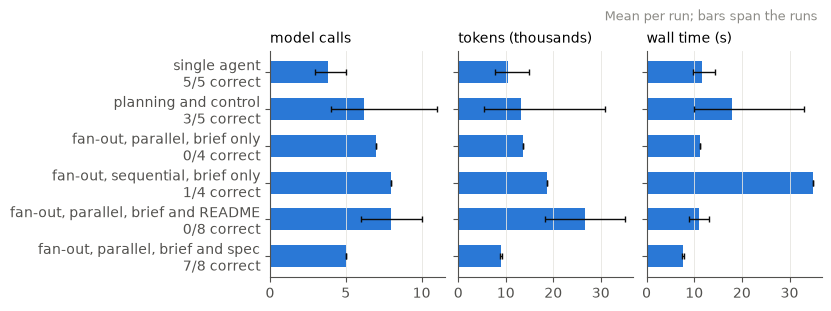

Whole notebook: 112 model calls, 159394 input and 73486 output tokens (0 reasoning), 0 s of rate-limit waits.


In [26]:
def bill(label, runs, correct):
    return {"organisation": label, "runs": len(runs),
            "calls": np.mean([r["calls"] for r in runs]),
            "input_tokens": np.mean([r["input_tokens"] for r in runs]),
            "output_tokens": np.mean([r["output_tokens"] for r in runs]),
            "wall_s": np.mean([r["wall_s"] for r in runs]),
            "tokens": np.mean([r["input_tokens"] + r["output_tokens"] for r in runs]),
            "calls_range": [min(r["calls"] for r in runs), max(r["calls"] for r in runs)],
            "tokens_range": [min(r["input_tokens"] + r["output_tokens"] for r in runs),
                             max(r["input_tokens"] + r["output_tokens"] for r in runs)],
            "wall_s_range": [min(r["wall_s"] for r in runs), max(r["wall_s"] for r in runs)],
            "correct": f"{sum(correct)}/{len(correct)}"}


BILL = [
    bill("single agent", SINGLE, [r["grade"] == "correct" for r in SINGLE]),
    bill("planning and control", PLANNED, [r["grade"] == "correct" for r in PLANNED]),
    bill("fan-out, parallel, brief only", [FAN["parallel"]],
         [r["grade"] == "correct" for r in fan_out_table(FAN["parallel"])]),
    bill("fan-out, sequential, brief only", [FAN["sequential"]],
         [r["grade"] == "correct" for r in fan_out_table(FAN["sequential"])]),
    bill("fan-out, parallel, brief and README", WITH_README, [r["grade"] == "correct" for r in with_readme]),
    bill("fan-out, parallel, brief and spec", WITH_SPEC, [r["grade"] == "correct" for r in with_spec]),
]
display(pd.DataFrame(BILL).drop(columns=["tokens", "calls_range", "tokens_range", "wall_s_range"]).round(1))


def plot_bill():
    fig, axes = plt.subplots(1, 3, figsize=(8.2, 3.0), sharey=True, layout="constrained")
    y = np.arange(len(BILL))
    for ax, (key, title) in zip(axes, [("calls", "model calls"), ("tokens", "tokens (thousands)"),
                                       ("wall_s", "wall time (s)")]):
        values = np.array([b[key] for b in BILL]) / (1e3 if key == "tokens" else 1)
        ranges = np.array([b[key + "_range"] for b in BILL]) / (1e3 if key == "tokens" else 1)
        ax.barh(y, values, height=0.6, color=BLUE)
        ax.errorbar(values, y, xerr=np.abs(ranges.T - values), fmt="none", ecolor=INK, elinewidth=1, capsize=2)
        ax.set_title(title, loc="left")
        ax.grid(axis="y", visible=False)
    axes[0].set_yticks(y, [f"{b['organisation']}\n{b['correct']} correct" for b in BILL])
    axes[0].invert_yaxis()
    fig.suptitle("Mean per run; bars span the runs", x=0.99, ha="right", fontsize=9, color=MUTED)
    return fig


fig = plot_bill()
save_figure(fig, "bill_per_organisation")
plt.show()

totals = [ledger.totals() for ledger in LEDGERS]
TOTAL = {"calls": sum(t["calls"] for t in totals), "input_tokens": sum(t["input_tokens"] for t in totals),
         "output_tokens": sum(t["output_tokens"] for t in totals),
         "reasoning_tokens": sum(t["reasoning_tokens"] for t in totals),
         "rate_limit_wait_s": sum(t["rate_limit_wait_s"] for t in totals)}
print(f"Whole notebook: {TOTAL['calls']} model calls, {TOTAL['input_tokens']} input and {TOTAL['output_tokens']} "
      f"output tokens ({TOTAL['reasoning_tokens']} reasoning), {TOTAL['rate_limit_wait_s']:.0f} s of rate-limit waits.")
MEASUREMENTS["bill"] = BILL
MEASUREMENTS["total"] = TOTAL
save_measurements()

### 7.2. Causes of failed executions

Each failed execution recorded the last line of its error output. The next cell sorts the messages into categories with fixed patterns, groups them with digits replaced by `N`, and names the runs in which each occurred. The first category collects calls to functions or arguments that the installed versions of NumPy, SciPy or pandas no longer provide; their number depends on the versions printed at the top of the notebook. The second collects scripts that use a variable defined in an earlier script: each script runs in a fresh process, so nothing persists between executions except files.

In [27]:
CATEGORIES = [  # first matching pattern wins
    ("library API changed or removed", r"unexpected keyword argument|has no attribute|cannot import name|only 0-dimensional"),
    ("name defined in another script", r"^NameError"),
    ("file not found", r"FileNotFoundError"),
    ("time limit", r"TimeoutExpired"),
    ("other", r"")]


def category(error):
    return next(name for name, pattern in CATEGORIES if re.search(pattern, error))


failures = [{"run": ledger.name, "category": category(e["error"]), "error": e["error"]}
            for ledger in LEDGERS for e in ledger.executions if not e["ok"]]
causes = {}
for f in failures:
    causes.setdefault((f["category"], re.sub(r"\d+", "N", f["error"])[:100]), []).append(f["run"])
display(pd.DataFrame([{"category": cat, "error": error, "count": len(runs), "runs": ", ".join(sorted(set(runs)))}
                      for (cat, error), runs in sorted(causes.items(), key=lambda item: (item[0][0], -len(item[1])))]))
print(f"{len(failures)} failed executions out of {sum(len(ledger.executions) for ledger in LEDGERS)}:",
      dict(Counter(f["category"] for f in failures)))
MEASUREMENTS["failures"] = failures
save_measurements()

,category,error,count,runs
0,file not found,FileNotFoundError: [Errno N] No such file or d...,2,"plan-1, plan-3"
1,file not found,FileNotFoundError: [Errno N] No such file or d...,2,"fan_spec_1, plan-3"
2,file not found,FileNotFoundError: [Errno N] No such file or d...,1,fan_readme_2
3,library API changed or removed,TypeError: only N-dimensional arrays can be co...,7,"fan_parallel, fan_readme_2, fan_sequential"
4,library API changed or removed,TypeError: read_csv() got an unexpected keywor...,6,"fan_parallel, fan_readme_2, fan_spec_2, single..."
5,library API changed or removed,AttributeError: module 'numpy' has no attribut...,2,"fan_parallel, fan_sequential"
6,library API changed or removed,ImportError: cannot import name 'cumtrapz' fro...,1,fan_sequential
7,name defined in another script,NameError: name 'n_sn' is not defined,2,"single-2, single-3"
8,name defined in another script,NameError: name 'n' is not defined. Did you me...,1,single-5
9,other,numpy.linalg.LinAlgError: Singular matrix,6,"fan_parallel, fan_readme_1, fan_readme_2, fan_..."


32 failed executions out of 69: {'library API changed or removed': 16, 'name defined in another script': 3, 'file not found': 5, 'other': 8}


### 7.3. Checklist

1. Measure one agent with a code-execution tool first. Its grades and its bill are the baseline for any other organisation.
2. Add planning, review and a separate writer when they correct errors that the single agent makes, and compare the grades of §2.2 and §3.2 before paying for the extra calls. A reviewer is itself a model, so its approval does not replace a deterministic test.
3. Fan out over parts that are independent. Concurrency shortens the wall time but does not reduce the number of tokens.
4. Pass the analysis conventions to every worker as an explicit object. Column names, and the documentation of the data, leave choices to the worker.
5. Compute derived numbers in code, and check every number of a report against the printed outputs.
6. Bound every loop: turns, attempts and rework rounds, and in a deployed system the tokens.

### 7.4. Exercises

#### Exercise 1: a plotting agent

(a) Add an agent `plotter` to the `Step` schema and to `PLANNER_SYSTEM`, with a node that asks for a script that saves the Hubble diagram with the fitted model to `hubble.png`.

(b) Route the new agent in `next_step` and adapt `normalise` so that a plotting step may follow the engineering steps.

(c) Run the graph once and compare its calls and tokens with the runs of §3.2.

#### Exercise 2: another provider

(a) Set `MODEL` to a model of another provider, install its LangChain package and set its API key.

(b) Run §2 and §3 with `REPEATS = 3`. Compare the grades, the covariance used and the bill with the saved run.

#### Exercise 3: deterministic checks inside the graphs

The spec of §5.3 states the conventions, but nothing checks that a script follows them, and nothing in §3 checks the report against the printed result.

(a) Write a function that receives a script, its `RESULT` line and the `AnalysisSpec`, and returns the requirements that they visibly violate: no reference to the covariance file, a number of light curves different from that of the cut, a redshift column other than `spec.z_column`.

(b) Call it in `solve` after a successful run, and return a violation to the engineer as feedback. Run the brief-only fan-out of §4.2 with the check. How many attempts does each worker need, and do the values agree with the references?

(c) In the planning-and-control graph, make the numeric fields of `Report` optional and add a node after the writer that compares its $\Omega_m$ with the `RESULT` line of the last engineering script. Route a mismatch, or a review that was not approved, to a report that states that the analysis failed.

#### Exercise 4: a token budget

(a) Give `Ledger` a token budget and make `ask` raise an exception when the tokens of the run would exceed it.

(b) Find the smallest budget with which the planning-and-control graph of §3 still returns a correct report, and compare it with the tokens of the single agent.

## Companion notebook

The same task with cmbagent_lg, traced with Langfuse: [`lecture01_cmbagent_lg.ipynb`](lecture01_cmbagent_lg.ipynb).